<h1 style="color:#003366;">NOVA IMS | MSc in Information Management</h1>
<h2 style="color:#006699;">Data Mining 2025/2026</h2>

<hr style="border:1px solid #006699;">

<h3><b>Group Project:</b> “Why are they not here today?”</h3>
<p><b>Notebook:</b> <i>Cluster Interpretation</i></p>

<h3>Group 16</h3>
<ul>
  <li><b>Beatriz Correia</b> – 20250895</li>
  <li><b>Filipa Brito</b> – 202211807</li>
  <li><b>Rita Silva</b> – 20221920</li>
  <li><b>Rodrigo Conceição</b> – 20220562</li>
</ul>

#### <font color='#006699'>Table of Contents </font> <a class="anchor" id='toc'></a> 
- [0. Imports](#p0)
- [1. Dataset Alignment and Cluster Size](#p1)
- [2. Numerical Feature Profiles (Bar Plots)](#p2)
- [3. Reasons for Absence by Cluster](#p3)
- [4. Temporal Patterns: Month of Absence and Day of the Week](#p4)
- [5. Multivariate Cluster Profiles (Radar Chart)](#p5)
- [6. Silhouette Analysis by Cluster](#p6)
- [7. Final Conclusions](#p7)
 

<font color='#006699' size=6>0. Imports</font> <a class="anchor" id="p0"></a>
  
[Back to TOC](#toc)

In [1]:
from sklearn.metrics import silhouette_samples
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df_raw = pd.read_csv("kmeans_k6_raw_with_cluster.csv")
df_scaled = pd.read_csv("kmeans_k6_scaled_with_cluster.csv")
absent_for_interpretation = pd.read_csv("absent_preprocessed.csv")

<font color='#006699' size=6>1. Dataset Alignment and Cluster Size</font> <a class="anchor" id="p1"></a>
  
[Back to TOC](#toc)

0    133
1    174
2     44
3    235
4    143
5     41
Name: cluster, dtype: int64


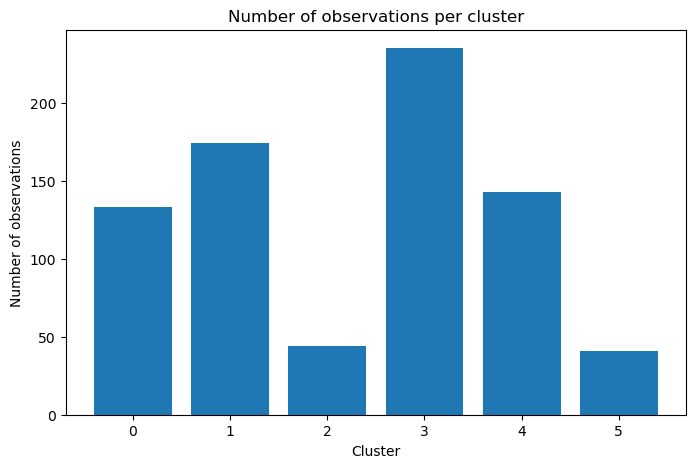

In [3]:
cluster_counts = df_raw["cluster"].value_counts().sort_index()
print(cluster_counts)
plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index, cluster_counts.values)
plt.xlabel("Cluster")
plt.ylabel("Number of observations")
plt.title("Number of observations per cluster")
plt.xticks(cluster_counts.index)
plt.show()

The final K-Means solution yields well-balanced clusters, ensuring that all identified segments are statistically meaningful and suitable for interpretation. None of the clusters are empty; the smallest cluster contains 41 observations, while the largest contains 235.

In [4]:
means_raw = df_raw.groupby("cluster").mean(numeric_only=True)
means_raw


,Transportation expense,Estimated commute time,Service time,Number of children,Social drinker,Number of pets,Absenteeism time in hours,Age,reason_freq,month_sin,month_cos,day_sin,day_cos
cluster,,,,,,,,,,,,,
0,191.368421,101.834586,18.127820,0.000000,0.962406,0.075188,4.308271,38.616541,0.109286,0.212199,0.126542,-0.026118,-0.009842
1,200.235632,33.850575,15.149425,1.396552,0.545977,0.442529,5.304598,43.431034,0.091499,0.098884,-0.162968,0.084568,-0.089858
2,220.113636,44.113636,13.863636,1.477273,0.795455,0.363636,34.000000,38.954545,0.053630,0.212048,-0.112820,0.160765,-0.263413
3,197.429787,41.868085,8.978723,0.438298,0.029787,0.770213,4.280851,31.123404,0.108953,0.127924,0.098554,-0.022876,-0.139257
4,285.181818,67.860140,12.104895,2.489510,1.000000,0.615385,5.769231,35.657343,0.104559,-0.133235,-0.008365,-0.093339,0.066313
5,338.926829,108.536585,3.975610,1.170732,0.829268,4.000000,6.975610,29.951220,0.065125,0.076438,-0.212101,0.090694,-0.091124


<font color='#006699' size=6>2. Numerical Feature Profiles (Bar Plots)</font> <a class="anchor" id="p2"></a>
  
[Back to TOC](#toc)

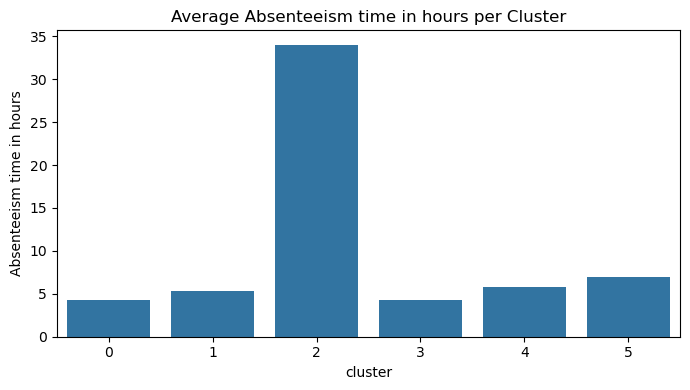

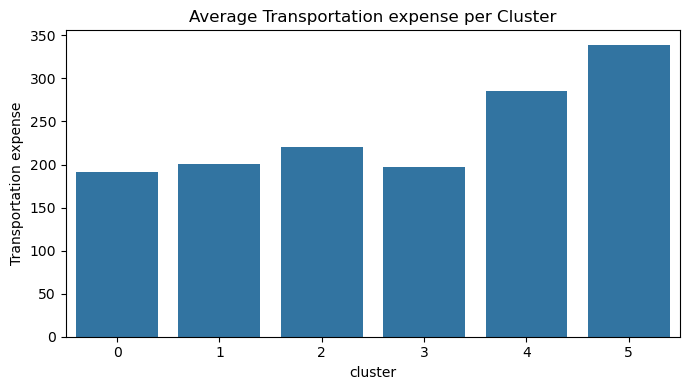

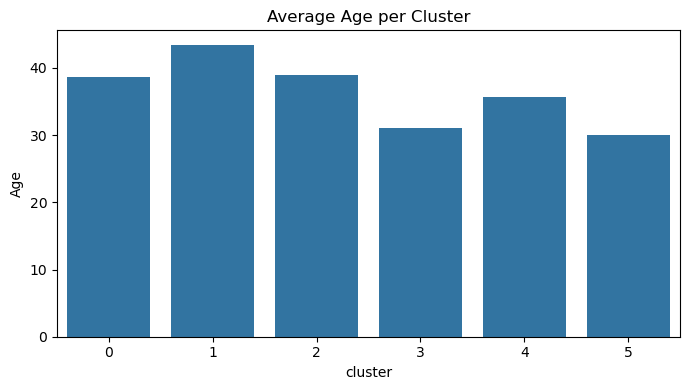

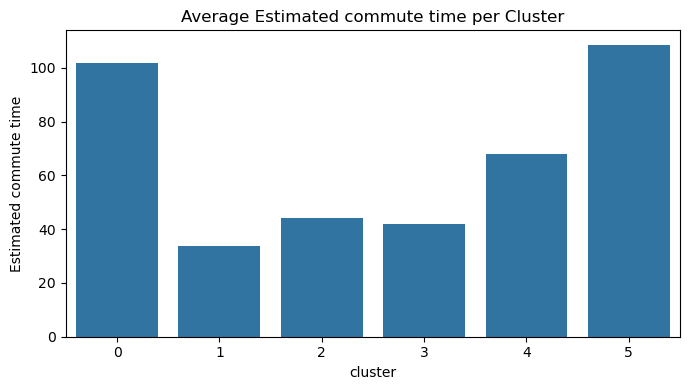

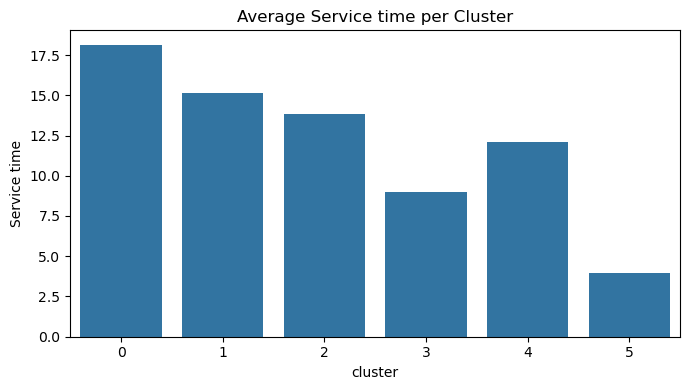

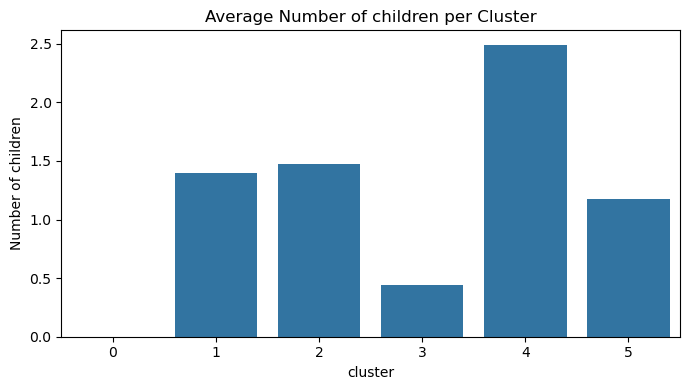

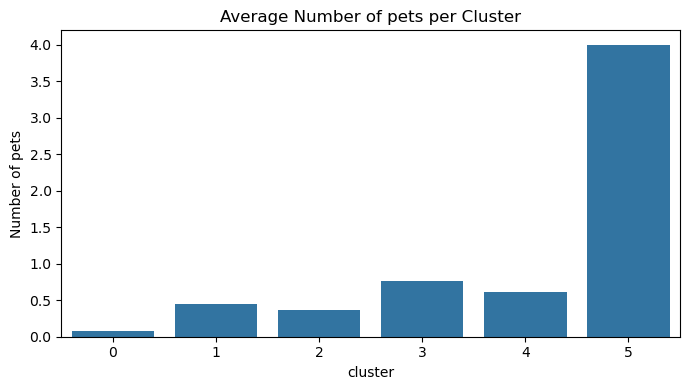

In [5]:
def bar_mean_by_cluster(df, feature, cluster_col="cluster"):
    plt.figure(figsize=(7,4))
    sns.barplot(data=df, x=cluster_col, y=feature, estimator="mean", errorbar=None)
    plt.title(f"Average {feature} per Cluster")
    plt.tight_layout()
    plt.show()

bar_mean_by_cluster(df_raw, "Absenteeism time in hours")
bar_mean_by_cluster(df_raw, "Transportation expense")
bar_mean_by_cluster(df_raw, "Age")
bar_mean_by_cluster(df_raw, "Estimated commute time")
bar_mean_by_cluster(df_raw, "Service time")
bar_mean_by_cluster(df_raw, "Number of children")
bar_mean_by_cluster(df_raw, "Number of pets")


The numerical profiles reveal distinct behavioral and demographic patterns, indicating that the clusters are not driven by noise but by meaningful differences in absenteeism intensity, mobility constraints, and career stage.

Across the numerical variables, the clusters show clear differentiation:

- **Absenteeism time in hours**: Strong variation across clusters, confirming that the segmentation captures different absenteeism behaviors.

- **Transportation expense & commute time**:Certain clusters exhibit higher commuting burden, suggesting a potential link between logistics and absenteeism.

- **Age & service time**: Some clusters concentrate younger, less tenured employees, while others reflect more experienced workers.

- **Number of children and pets**: There is substantial variation across the clusters. Some clusters have a higher number of children but fewer pets, while others show the opposite pattern. Additionally, some clusters contain members with neither children nor pets.

<font color='#006699' size=6>3. Reasons for Absence by Cluster</font> <a class="anchor" id="p5"></a>
  
[Back to TOC](#toc)

In [6]:
df_cat = absent_for_interpretation.copy()
df_cat["cluster"] = df_raw["cluster"].values

In [7]:
top_reasons = (
    df_cat["Reason for absence"]
    .value_counts()
    .head(8)
    .index
)

df_reason_top = df_cat[df_cat["Reason for absence"].isin(top_reasons)]


In [8]:
reason_pct = (
    pd.crosstab(
        df_reason_top["cluster"],
        df_reason_top["Reason for absence"],
        normalize="index"
    ) * 100
).round(1)


In [9]:
top_reasons = (
    df_cat["Reason for absence"]
    .value_counts()
    .head(8)
    .index
)

reason_pct = reason_pct[top_reasons]


In [10]:
def plot_reasons_per_cluster_horizontal(reason_pct, cluster_id):
    data = reason_pct.loc[cluster_id].sort_values()

    plt.figure(figsize=(8,4))
    data.plot(kind="barh")
    plt.xlabel("Percentage within cluster (%)")
    plt.title(f"Cluster {cluster_id} – Main Reasons for Absence")
    plt.tight_layout()
    plt.show()


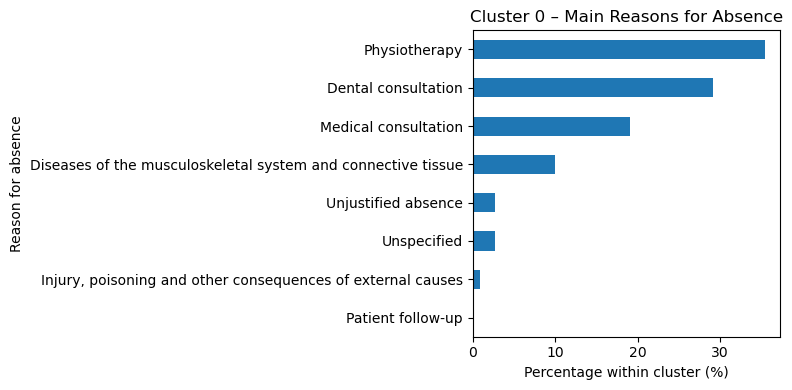

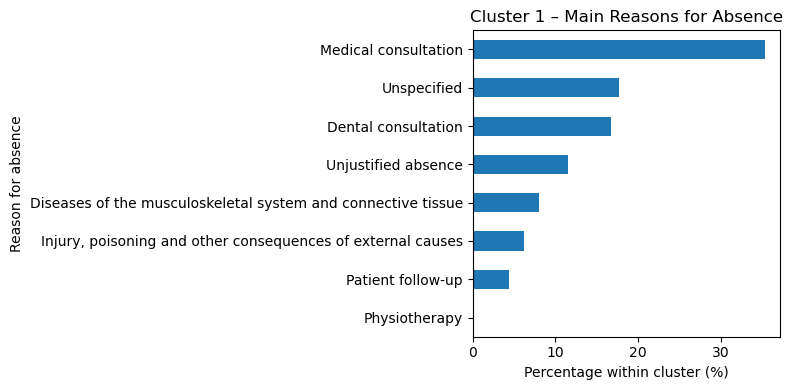

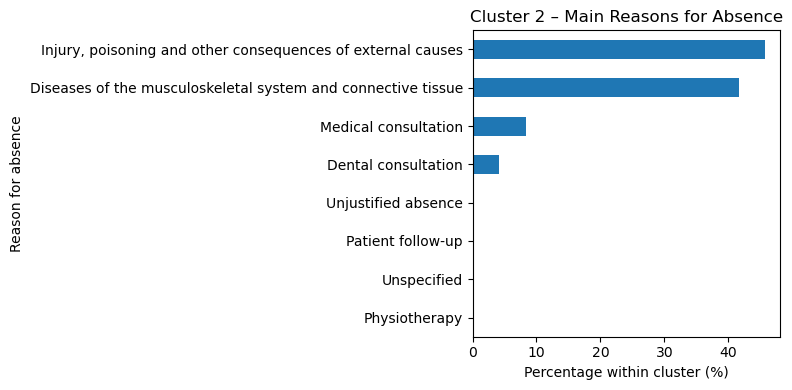

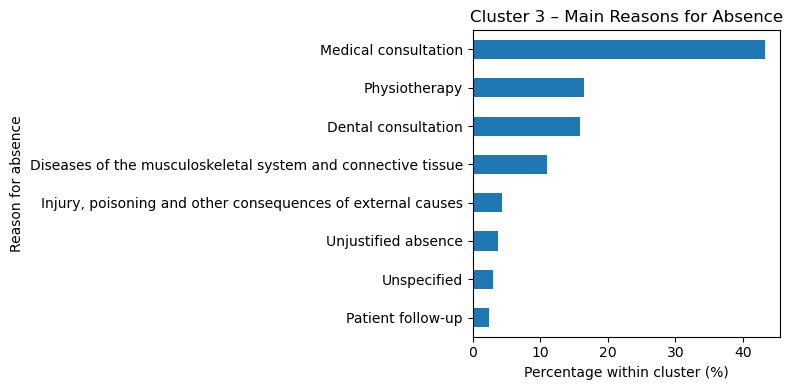

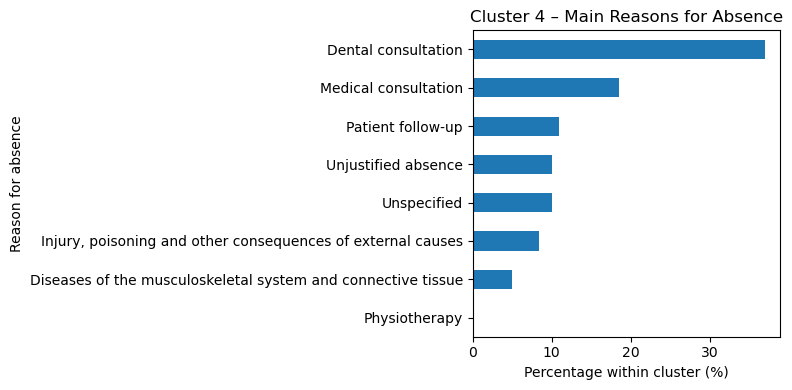

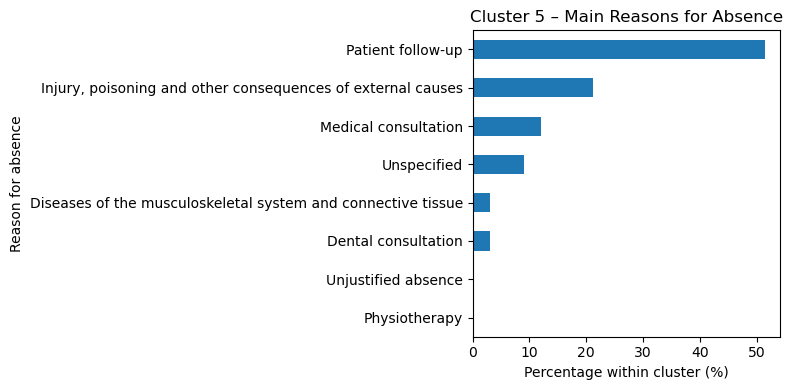

In [11]:
for c in reason_pct.index:
    plot_reasons_per_cluster_horizontal(reason_pct, c)


The distribution of absence reasons provides strong semantic meaning to the clusters, linking quantitative segmentation to real-world absenteeism drivers.

Each cluster is characterized by distinct dominant reasons, all related to medical care:
- **cluster 1**: Medical consultation
- **cluster 2**: Injury, poisoning and other consequences of external causes
- **cluster 3**: Medical consultation
- **cluster 4**: Dental consultation
- **cluster 5**: Patient follow-up

<font color='#006699' size=6>4. Temporal Patterns: Month of Absence and Day of the Week</font> <a class="anchor" id="p6"></a>
  
[Back to TOC](#toc)

In [12]:
# Month of absence
month_pct = (
    pd.crosstab(
        df_cat["cluster"],
        df_cat["Month of absence"],
        normalize="index"
    ) * 100
).round(1)

# Day of the week
day_pct = (
    pd.crosstab(
        df_cat["cluster"],
        df_cat["Day of the week"],
        normalize="index"
    ) * 100
).round(1)


In [13]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

month_pct = month_pct.reindex(columns=[m for m in month_order if m in month_pct.columns])

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
day_pct = day_pct.reindex(columns=[d for d in day_order if d in day_pct.columns])


In [14]:
def plot_month_per_cluster_h(month_pct, cluster_id):
    data = month_pct.loc[cluster_id]
    plt.figure(figsize=(8,4))
    data.plot(kind="barh")
    plt.xlabel("Percentage within cluster (%)")
    plt.title(f"Cluster {cluster_id} – Month of Absence")
    plt.tight_layout()
    plt.show()

def plot_day_per_cluster_h(day_pct, cluster_id):
    data = day_pct.loc[cluster_id]
    plt.figure(figsize=(8,4))
    data.plot(kind="barh")
    plt.xlabel("Percentage within cluster (%)")
    plt.title(f"Cluster {cluster_id} – Day of the Week")
    plt.tight_layout()
    plt.show()


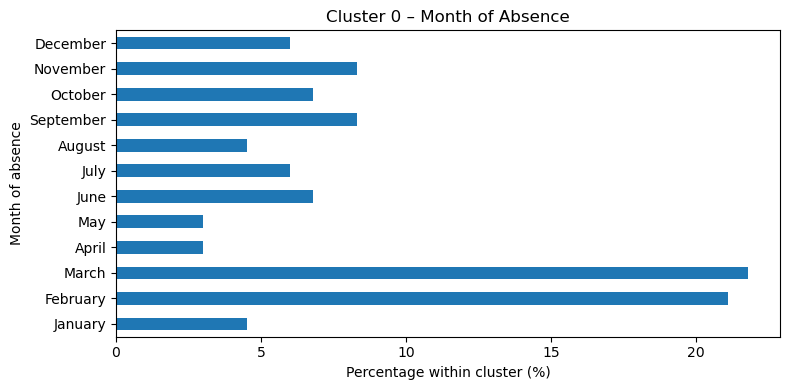

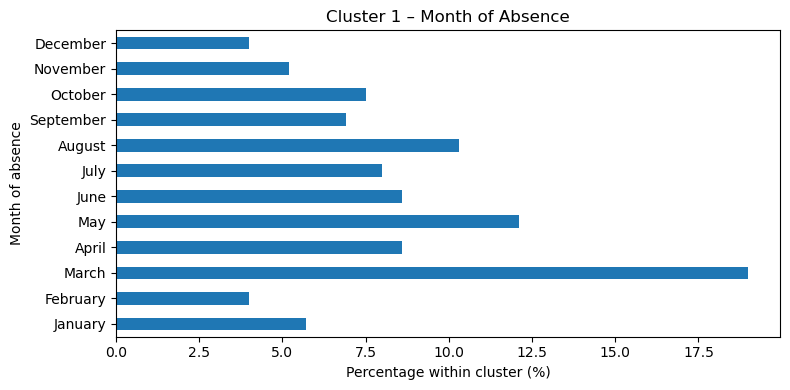

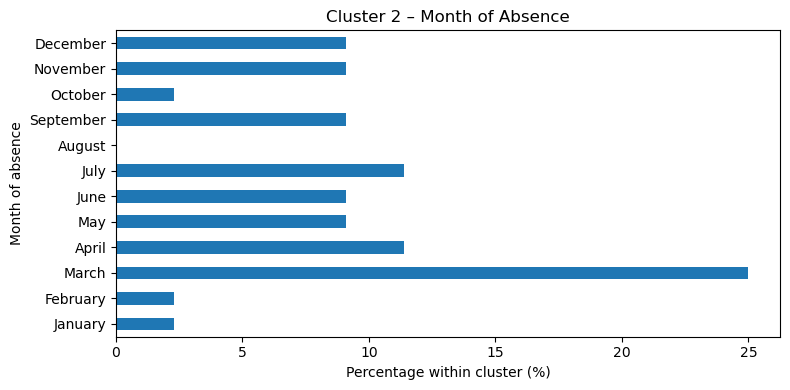

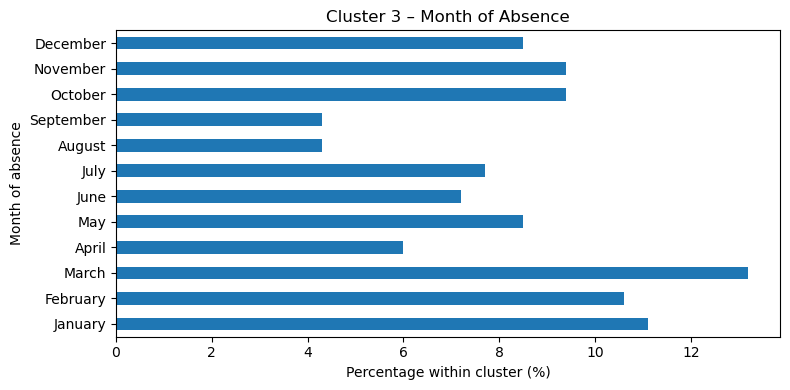

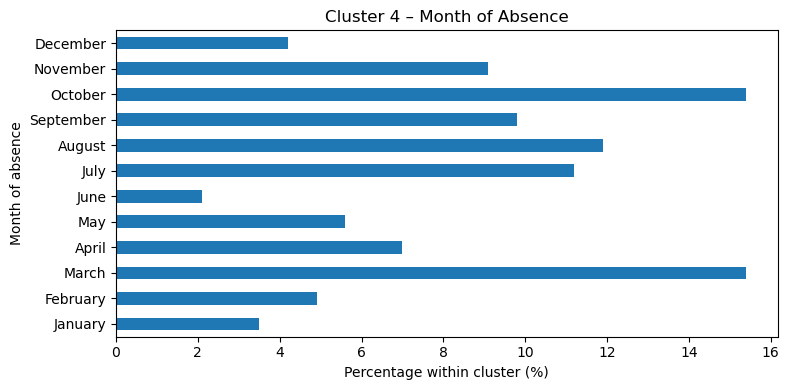

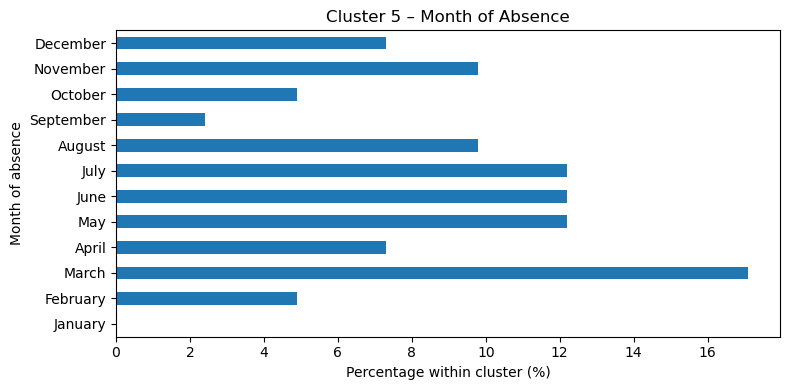

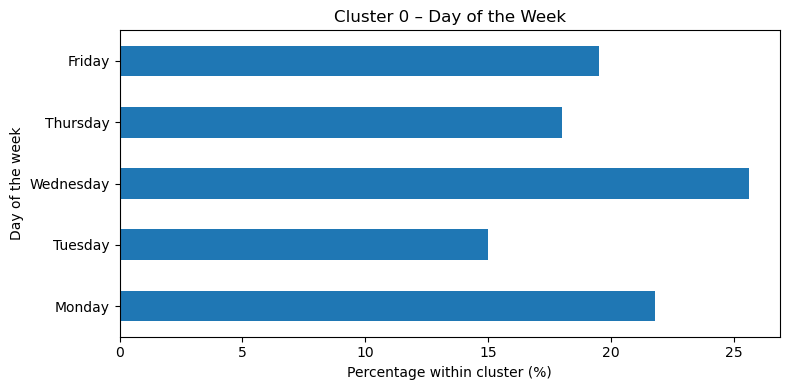

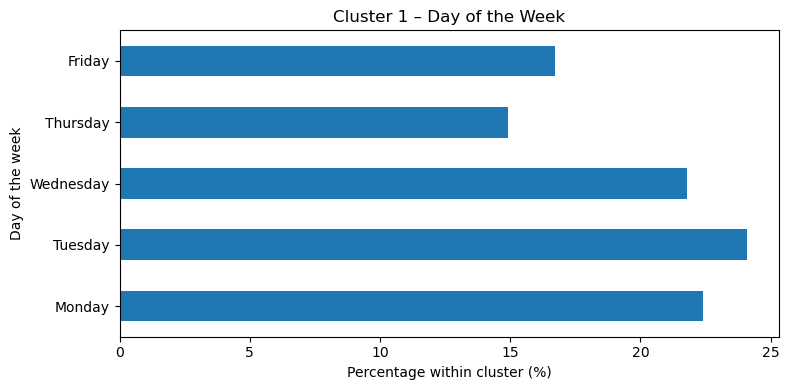

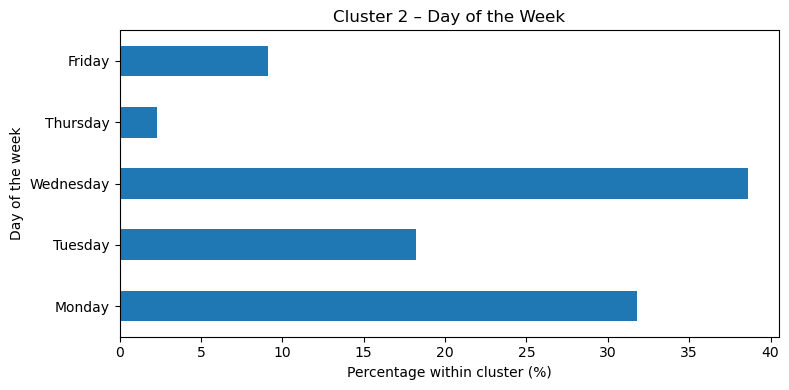

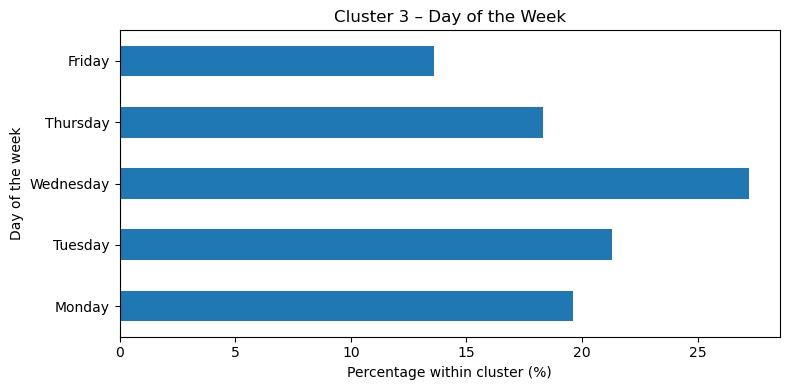

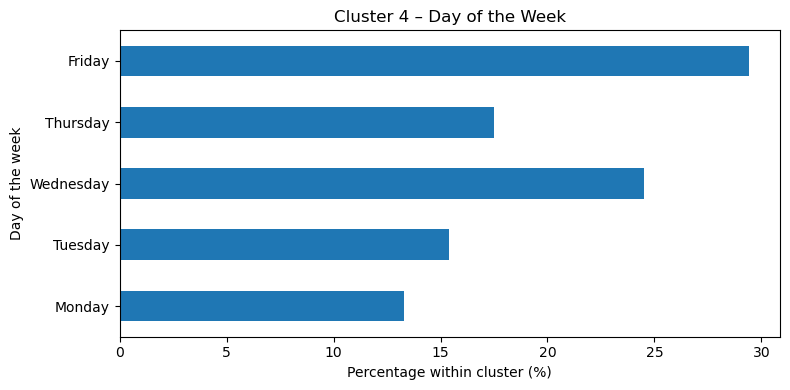

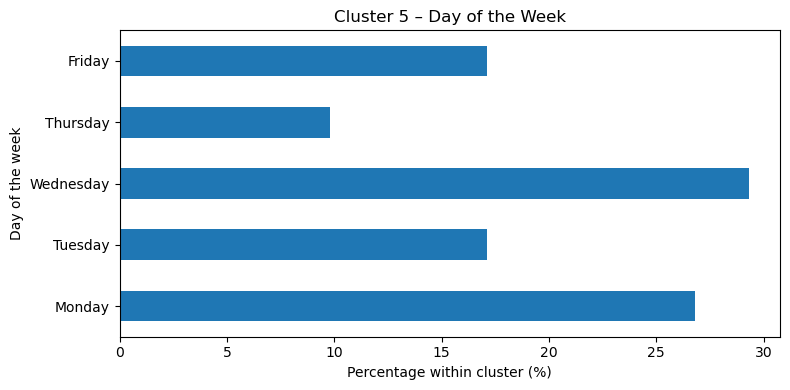

In [15]:
for c in month_pct.index:
    plot_month_per_cluster_h(month_pct, c)

for c in day_pct.index:
    plot_day_per_cluster_h(day_pct, c)

Temporal patterns for the **Month of Absence** do not differ substantially across clusters, suggesting that seasonality plays a role in specific absenteeism profiles, which can inform targeted planning and resource allocation.<br>
Most of the clusters show seasonal concentration around March.

**Weekly patterns** reveal differences between routine-driven absences and more irregular behaviors, providing additional insights into cluster characteristics.<br>
Some clusters show higher absence rates at the beginning or end of the week; however, Wednesday emerges as the day with the highest absences across most clusters.

<font color='#006699' size=6>5. Multivariate Cluster Profiles (Radar Chart)</font> <a class="anchor" id="p5"></a>
  
[Back to TOC](#toc)

In [16]:
features_radar = [
    "Absenteeism time in hours",
    "Age",
    "Service time",
    "Transportation expense",
    "Estimated commute time",
    "Number of children",
    "Social drinker"
]


In [17]:
def radar_cluster_profile(df, cluster_col, features, title):
    cluster_means = df.groupby(cluster_col)[features].mean()

    labels = features
    num_vars = len(labels)

    angles = np.linspace(0, 2*np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(9,9), subplot_kw=dict(polar=True))

    for cluster in cluster_means.index:
        values = cluster_means.loc[cluster].values.tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, label=f"Cluster {cluster}")
        ax.fill(angles, values, alpha=0.12)

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), labels)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_title(title, fontsize=16, pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15))

    plt.tight_layout()
    plt.show()


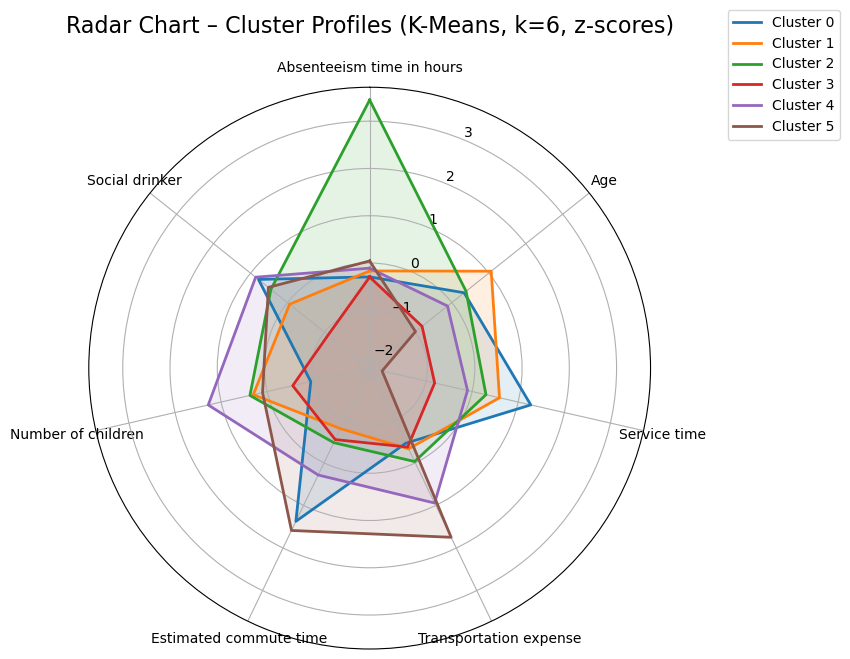

In [18]:
radar_cluster_profile(
    df_scaled,
    cluster_col="cluster",
    features=features_radar,
    title="Radar Chart – Cluster Profiles (K-Means, k=6, z-scores)"
)


The radar chart highlights clear multivariate signatures for each cluster, reinforcing the interpretability and internal coherence of the K-Means solution.<br>
Each cluster presents a unique shape, confirming multidimensional differentiation

Some clusters are characterized by:
- Higher absenteeism duration
- Higher commuting costs
- Larger family responsibilities
- Others show consistently lower values across most dimensions

<font color='#006699' size=6>6. Silhouette Analysis by Cluster</font> <a class="anchor" id="p6"></a>
  
[Back to TOC](#toc)

In [19]:
sil_samples = silhouette_samples(df_scaled, df_raw["cluster"])


In [20]:
df_sil = pd.DataFrame({
    "cluster": df_raw["cluster"],
    "silhouette": sil_samples
})


In [21]:
sil_by_cluster = df_sil.groupby("cluster")["silhouette"].mean()
sil_by_cluster


cluster
0    0.320566
1    0.127000
2    0.198741
3    0.225171
4    0.263719
5    0.361877
Name: silhouette, dtype: float64

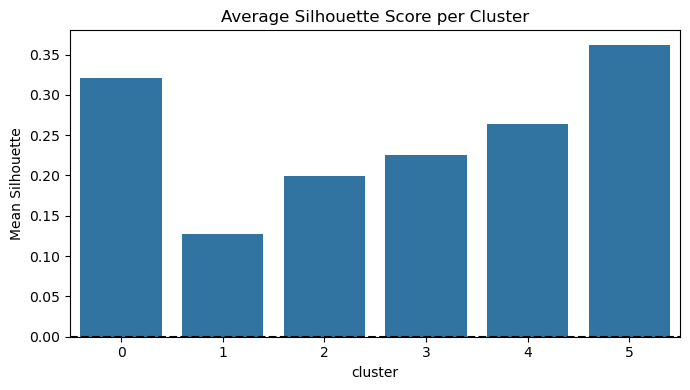

In [22]:
plt.figure(figsize=(7,4))
sns.barplot(
    data=df_sil,
    x="cluster",
    y="silhouette",
    estimator="mean",
    errorbar=None
)
plt.axhline(0, color="black", linestyle="--")
plt.title("Average Silhouette Score per Cluster")
plt.ylabel("Mean Silhouette")
plt.tight_layout()
plt.show()


Althouh, some clusters are more compact and better separated than others, the silhouette analysis confirms that all six clusters are well-formed, with acceptable internal cohesion and separation.

<font color='#006699' size=6>7. Final Conclusions</font> <a class="anchor" id="p7"></a>
  
[Back to TOC](#toc)

The six clusters identified by the K-Means algorithm represent distinct and interpretable absenteeism profiles, differing across absenteeism intensity, commuting burden, demographic characteristics, absence reasons, and temporal patterns.
<br>
The consistency between numerical variables, categorical distributions, and silhouette-based validation confirms that the segmentation is both statistically robust and substantively meaningful.
<br>
These clusters provide a strong foundation for actionable Human Resources strategies, enabling targeted interventions tailored to the specific drivers of absenteeism observed in each group.

In [23]:
df_powerbi = absent_for_interpretation.copy()

df_powerbi["cluster"] = df_raw["cluster"].values


In [24]:
df_powerbi.to_csv("absenteeism_clusters_powerbi.csv", index=False)